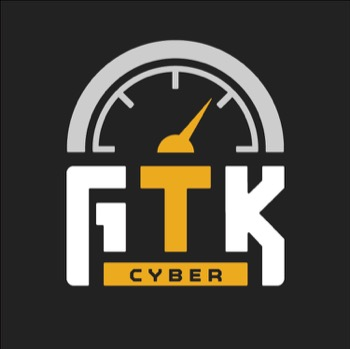


# Worksheet 1.1:  Vectorized Data Structures - Answers
This worksheet covers concepts covered in Module 1 - Vectorized Data Structures.  It should take no more than 20-30 minutes to complete.  Please raise your hand if you get stuck.

You may of course use AI to generate answers, but we would **strongly** encourage you to make sure you are familiar with the concepts presented in this module as they are core foundational concepts for both machine learning and artificial intelligence.

There are many ways to accomplish the tasks that you are presented with, however you will find that by using the techniques covered in class, the exercises should be relatively simple.

## Import the Libraries
For this exercise, we will be using:
* Pandas (http://pandas.pydata.org/pandas-docs/stable/)
* ipaddress (https://docs.python.org/3/library/ipaddress.html)
* apachelogs (https://pypi.org/project/apachelogs/)
* user_agents (https://pypi.org/project/user-agents/)

In [ ]:
# --- data-loader (local files / Databricks volume) ---
import os
import tempfile
try:
    dbutils  # defined only on Databricks
    DATA_HOME = os.environ.get("COURSE_DATA_HOME", "/Volumes/ai_cyber_bootcamp/course/data/")
    WORK_HOME = os.path.abspath("../work") + "/"
    SCRATCH_HOME = tempfile.gettempdir()
    ON_DATABRICKS = True
except NameError:
    DATA_HOME = "../data/"
    WORK_HOME = DATA_HOME
    SCRATCH_HOME = WORK_HOME
    ON_DATABRICKS = False
os.makedirs(WORK_HOME, exist_ok=True)

def handoff(name):
    """Output of an earlier worksheet: the student's own copy if it exists, else the shipped one."""
    p = WORK_HOME + name
    return p if os.path.exists(p) else DATA_HOME + name
# --- end data-loader ---


In [1]:
import pandas as pd
from ipaddress import ip_address
from apachelogs import LogParser

# Set the `DATA_HOME` Variable
All the labs will be using various data files from this repository.  If you cloned the repository to your local machine, you shouldn't have to change this variable.  If not, you will need to change it to the path where you downloaded the class data files.

In [2]:
# DATA_HOME comes from the data-loader cell at the top of this notebook

## Exercise 1:  Splitting and Filtering a Series

In this exercise, you are given a list of email addresses called `emails`.  Your goal is to find the email accounts from domains that end in `.edu`.  To accomplish this, you will need to:
1. Filter the series to remove the emails that do not end in .edu
2. Extract the accounts.

If you get stuck, refer to the documentation for Pandas string manipulation (https://pandas.pydata.org/pandas-docs/stable/user_guide/text.html) or the slides.  Note that there are various functions to accomplish this task.

In [9]:
emails = ['alawrence0@prlog.org',
'blynch1@businessweek.com',
'mdixon2@cmu.edu',
'rvasquez3@1688.com',
'astone4@creativecommons.org',
'mcarter5@chicagotribune.com',
'dcole6@vinaora.com',
'kpeterson7@topsy.com',
'ewebb8@cnet.com',
'jtaylor9@google.ru',
'ecarra@buzzfeed.com',
'jjonesb@arizona.edu',
'jbowmanc@disqus.com',
'eduardo_sanchezd@npr.org',
'emooree@prweb.com',
'abbedu@google.com',
'eberryf@brandeis.edu',
'sgardnerh@wikipedia.org',
'balvarezi@delicious.com',
'blewisj@privacy.gov.au']

In [10]:
email_series = pd.Series(emails)
filtered_emails = email_series[email_series.str.contains(r'\.edu')]
print( filtered_emails )

2          mdixon2@cmu.edu
11     jjonesb@arizona.edu
16    eberryf@brandeis.edu
dtype: object


In [11]:
accounts = filtered_emails.str.split('@').str[0]
print( accounts )

2     mdixon2
11    jjonesb
16    eberryf
dtype: object


In [12]:
email_series[email_series.str.contains(r'\.edu')].str.split('@').str[0]

2     mdixon2
11    jjonesb
16    eberryf
dtype: object

## Exercise 2: Manipulating a Series

You are given a Series of IP Addresses and the goal is to limit this data to private IP addresses.  Python has an `ipaddress` module which provides the capability to create, manipulate and operate on IPv4 and IPv6 addresses and networks.  Complete documentation is available here: https://docs.python.org/3/library/ipaddress.html.

Here are some examples of how you might use this module:

```python
myIP = ipaddress.ip_address( '192.168.0.1' )
myNetwork = ipaddress.ip_network( '192.168.0.0/28' )

#Check membership in network
if myIP in myNetwork:  #This works
    print( "Yay!" )

#Loop through CIDR blocks
for ip in myNetwork:
    print( ip )

192.168.0.0
192.168.0.1
…
…
192.168.0.13
192.168.0.14
192.168.0.15

#Testing to see if an IP is private
if myIP.is_private:
    print( "This IP is private" )
else:
    print( "Routable IP" )

```

1.  First, write a function which takes an IP address and returns true if the IP is private, false if it is public.  HINT:  use the ```ipaddress``` module.
2.  Next, use this to create a Series of true/false values in the same sequence as your original Series.
3.  Finally, use this to filter out the original Series so that it contains only private IP addresses.

In [2]:
hosts = [ '192.168.1.2', '10.10.10.2', '172.143.23.34', '34.34.35.34', '172.15.0.1', '172.17.0.1']

In [3]:
def is_private(x):
    return ip_address(x).is_private

In [4]:
is_private('192.168.0.1')


True

In [5]:
IPData = pd.Series(hosts)
privateIPs = IPData[IPData.apply(lambda x: ip_address(x).is_private)]
print(privateIPs)

0    192.168.1.2
1     10.10.10.2
5     172.17.0.1
dtype: object


In [6]:
IPData[IPData.apply(is_private)]

0    192.168.1.2
1     10.10.10.2
5     172.17.0.1
dtype: object

## Exercise 3:
You have been given a list of US phone numbers.  The area code is the first three digits.  Your task is to produce a summary of how many times each area code appears in the list. To do this you will need to:
1. Extract the area code from each phone number
2. Count the unique occurrences.

In [13]:
phone_numbers = [
'(833) 759-6854',
'(811) 268-9951',
'(855) 449-4648',
'(833) 212-2929',
'(833) 893-7475',
'(822) 346-3086',
'(844) 259-9074',
'(855) 975-8945',
'(811) 385-8515',
'(811) 523-5090',
'(844) 593-5677',
'(833) 534-5793',
'(899) 898-3043',
'(833) 662-7621',
'(899) 146-8244',
'(822) 793-4965',
'(822) 641-7853',
'(833) 153-7848',
'(811) 958-2930',
'(822) 332-3070',
'(833) 223-1776',
'(811) 397-1451',
'(844) 096-0377',
'(822) 000-0717',
'(899) 311-1880']

In [14]:
phone_number_series = pd.Series(phone_numbers)

There are many methods that can solve this, below are 3 of them. You may have used something else which is great as long as you get the right answers.

### Method 1
- Extract the 1,2,3rd characters from the string using the slice method

In [15]:
area_codes = phone_number_series.str.slice(1,4)
area_codes.value_counts()

833    7
811    5
822    5
844    3
899    3
855    2
Name: count, dtype: int64

### Method 2
- Extract the first three digits using the extract method and string formatting

In [16]:
area_codes2 = phone_number_series.str.extract(r'\((\d{3})\)', expand=False)
area_codes2.value_counts()

833    7
811    5
822    5
844    3
899    3
855    2
Name: count, dtype: int64

### Method 3
- Split the string on the right parens
- Extract the 0th item from that list
- Replace the left parens with nothing

In [17]:
area_codes3 = phone_number_series.str.split(')').str[0].str.replace('(','')
area_codes3.value_counts()

833    7
811    5
822    5
844    3
899    3
855    2
Name: count, dtype: int64

In [18]:
area_codes.describe()

count      25
unique      6
top       833
freq        7
dtype: object

# Part 2:  DataFrames
This next part of the lab will focus on working with two dimensional data, also known as dataframes.  Most security data should be mapped to 2D tables, so this section is vital to understanding how to access security data sets.  These exercises will walk you through the process of getting data into a dataframe and then manipulating that data.

## Exercise 4:
In the data file, there is a webserver file called `hackers-access.httpd`.  For this exercise, you will use this file to answer the following questions:
1.  Which browsers are the top 3 most used browsers in this data?
2.  Which are the least (3) used operating systems?

In order to accomplish this task, do the following:
1. Parse each log to pull out the following relevant information
        - user agent, bytes, status, remote host, number of bytes sent
2. For each log, store the raw text and each piece of information in a data frame
3.  Write a function which takes a User Agent string as an argument and returns the name of the operating system and the browser family.  HINT:  You might want to use `user_agents` module, the documentation for which is available here: (https://pypi.python.org/pypi/user-agents)
4.  Next, apply this function to the column which contains the user agent string
5.  Store this series as a new column in the dataframe
6.  Count the occurrences of each value in the new columns (top 5 is fine)

First we need to grab another Python library with pip
[https://pypi.org/project/apachelogs/](https://pypi.org/project/apachelogs/)

In [20]:
line_parser = LogParser("%h %l %u %t \"%r\" %>s %b \"%{Referer}i\" \"%{User-agent}i\"")

raw_text_log = '192.161.57.88 - - [30/Oct/2015:15:59:39 +0100] "POST /login_form HTTP/1.1" 200 18354 "http://niels.basjes.nl/login_form" "Mozilla/5.0 (Windows NT 6.1; rv:32.0) Gecko/20100101 Firefox/32.0"'

log_dict = {}
log_dict = line_parser.parse(raw_text_log)
log_dict.entry

'192.161.57.88 - - [30/Oct/2015:15:59:39 +0100] "POST /login_form HTTP/1.1" 200 18354 "http://niels.basjes.nl/login_form" "Mozilla/5.0 (Windows NT 6.1; rv:32.0) Gecko/20100101 Firefox/32.0"'

In [22]:
#Read in the log file
server_log = open(DATA_HOME + "hackers-access.httpd", "r")

#Create an empty dataframe
parsed_server_data = pd.DataFrame()

# read and parse each line and store the information in the columns of the dataframe
for num, line in enumerate(server_log):
    data = {}
    data = line_parser.parse(line)
    parsed_server_data.loc[num,'raw_log']= data.entry
    parsed_server_data.loc[num,'remote_host']= data.remote_host
    parsed_server_data.loc[num,'user_agent']=data.headers_in["User-agent"]
    parsed_server_data.loc[num,'request_time']=data.request_time
    parsed_server_data.loc[num,'status']=data.final_status
    parsed_server_data.loc[num,'bytes']=data.bytes_sent

parsed_server_data.head()

,raw_log,remote_host,user_agent,request_time,status,bytes
0,195.154.46.135 - - [25/Oct/2015:04:11:25 +0100...,195.154.46.135,Mozilla/5.0 (Windows NT 5.1; rv:35.0) Gecko/20...,2015-10-25 04:11:25+01:00,200.0,24323.0
1,23.95.237.180 - - [25/Oct/2015:04:11:26 +0100]...,23.95.237.180,Mozilla/5.0 (Windows NT 5.1; rv:35.0) Gecko/20...,2015-10-25 04:11:26+01:00,200.0,11114.0
2,23.95.237.180 - - [25/Oct/2015:04:11:27 +0100]...,23.95.237.180,Mozilla/5.0 (Windows NT 5.1; rv:35.0) Gecko/20...,2015-10-25 04:11:27+01:00,302.0,9093.0
3,158.222.5.157 - - [25/Oct/2015:04:24:31 +0100]...,158.222.5.157,Mozilla/5.0 (Windows NT 6.3; WOW64; rv:34.0) G...,2015-10-25 04:24:31+01:00,200.0,11114.0
4,158.222.5.157 - - [25/Oct/2015:04:24:32 +0100]...,158.222.5.157,Mozilla/5.0 (Windows NT 6.3; WOW64; rv:34.0) G...,2015-10-25 04:24:32+01:00,302.0,9093.0


In [28]:
# Step 3: Fix the functions to parse os and family from the user_agent column
from user_agents import parse

def get_os(x:str):
    user_agent_os = parse(x).get_os()
    return user_agent_os

def get_browser(x):
    user_agent_browser = parse(x).get_browser()
    return user_agent_browser

In [29]:
#Apply the functions to the dataframe
parsed_server_data['os'] = parsed_server_data['user_agent'].apply( get_os )
parsed_server_data['browser'] = parsed_server_data['user_agent'].apply( get_browser )

In [30]:
parsed_server_data.sample(5)

,raw_log,remote_host,user_agent,request_time,status,bytes,os,browser
1633,31.220.113.224 - - [27/Oct/2015:19:03:35 +0100...,31.220.113.224,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,2015-10-27 19:03:35+01:00,200.0,24319.0,Windows 7,Chrome 39.0.2171
20,89.42.237.71 - - [25/Oct/2015:05:06:42 +0100] ...,89.42.237.71,Mozilla/5.0 (Windows NT 5.1; rv:34.0) Gecko/20...,2015-10-25 05:06:42+01:00,200.0,12191.0,Windows XP,Firefox 34.0
916,192.119.149.217 - - [26/Oct/2015:14:22:28 +010...,192.119.149.217,Mozilla/5.0 (Windows NT 6.3; WOW64; Trident/7....,2015-10-26 14:22:28+01:00,200.0,11793.0,Windows 8.1,IE 11.0
2226,216.158.200.122 - - [28/Oct/2015:17:18:12 +010...,216.158.200.122,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,2015-10-28 17:18:12+01:00,200.0,18354.0,Windows 7,Opera 26.0.1656
1843,216.158.197.69 - - [28/Oct/2015:04:16:10 +0100...,216.158.197.69,Mozilla/5.0 (Windows NT 6.1) AppleWebKit/537.3...,2015-10-28 04:16:10+01:00,200.0,12191.0,Windows 7,Chrome 39.0.2171


In [31]:
#Step 6: Count the values in new columns
parsed_server_data['os'].value_counts()

os
Windows 7              2041
Windows Vista           500
Windows XP              423
Windows 8.1             221
Linux                   125
Mac OS X 10.10.1         66
Chrome OS 6310.68.0      60
Mac OS X 10.8.4          12
Ubuntu                    6
Mac OS X 10.10.0          2
Name: count, dtype: int64

In [32]:
parsed_server_data['browser'].value_counts()

browser
Chrome 39.0.2171    717
Opera 26.0.1656     556
Firefox 34.0        553
Dragon 36.1.1       533
Firefox 35.0        502
Firefox 32.0        326
Firefox 17.0         95
IE 11.0              78
Chrome 26.0.1410     24
Chrome 27.0.1453     24
Safari 8.0.2         24
Chrome 13.0.782      12
Chrome 28.0.1500     12
Name: count, dtype: int64

# Putting it All Together:  Data Analysis
In this next section, you will be using Pandas to answer some analytic questions from a dataset.  You will need to create a data frame from the `dailybots.csv` file which can be found in the `data` directory.  You should be able to do this with the `pd.read_csv()` function.  Take a minute to look at the dataframe because we are going to be using it for the last few exercises.

In [35]:
data = pd.read_csv( DATA_HOME + 'dailybots.csv' )
data.sample(10)

,date,botfam,industry,hosts,orgs
3825,2016-08-08,PushDo,Manufacturing,419,7
728,2016-06-13,Zeus,Healthcare/Wellness,8,7
44,2016-06-01,Zeus,Education,61,31
1196,2016-06-22,ConfickerAB,Finance,279,55
1623,2016-06-29,zeroaccess,Government/Politics,13,6
4041,2016-08-12,PushDo,Government/Politics,71,3
3756,2016-08-07,ConfickerAB,Finance,223,38
970,2016-06-18,ConfickerAB,Education,384,76
3522,2016-08-02,Zusy,Education,34,17
1418,2016-06-26,Bedep,Healthcare/Wellness,18,6


In [34]:
data.describe()

,hosts,orgs
count,4969.000000,4969.00000
mean,142.308110,15.31133
std,240.955294,21.15150
min,1.000000,1.00000
25%,10.000000,3.00000
50%,38.000000,7.00000
75%,187.000000,16.00000
max,2031.000000,122.00000


## Exercise 5: Which industry sees the most Ramnit infections? Least?

Count the number of infected days for "Ramnit" in each industry.
How:
1.  First filter the data to remove all the infections we don't care about
2.  Aggregate the data on the column of interest. HINT:  You might want to use the `groupby()` function
3.  Add up the results

In [36]:
grouped_df = data[data['botfam'] == "Ramnit"].groupby(['industry'], as_index=False)
grouped_df.sum()

,industry,date,botfam,hosts,orgs
0,Education,2016-06-012016-06-022016-06-032016-06-042016-0...,RamnitRamnitRamnitRamnitRamnitRamnitRamnitRamn...,7492,3949
1,Finance,2016-06-012016-06-022016-06-032016-06-042016-0...,RamnitRamnitRamnitRamnitRamnitRamnitRamnitRamn...,2281,1357
2,Government/Politics,2016-06-012016-06-022016-06-032016-06-042016-0...,RamnitRamnitRamnitRamnitRamnitRamnitRamnitRamn...,4484,448
3,Healthcare/Wellness,2016-06-012016-06-022016-06-032016-06-042016-0...,RamnitRamnitRamnitRamnitRamnitRamnitRamnitRamn...,544,473
4,Manufacturing,2016-06-012016-06-022016-06-032016-06-042016-0...,RamnitRamnitRamnitRamnitRamnitRamnitRamnitRamn...,46303,1155
5,Retail,2016-06-012016-06-022016-06-032016-06-042016-0...,RamnitRamnitRamnitRamnitRamnitRamnitRamnitRamn...,17649,558


# Exercise 6: Calculate the min, max, median and mean infected orgs for each bot family, sort by median
In this exercise, you are asked to calculate the min, max, median and mean of infected orgs for each bot family sorted by median.
1.  Using the `groupby()` function, create a grouped data frame
2.  You can do this one metric at a time OR you can use the .agg() function. You might want to refer to the documentation here:  http://pandas.pydata.org/pandas-docs/stable/groupby.html#applying-multiple-functions-at-once
3.  Sort the values (HINT HINT) by the median column

In [38]:
group2 = data[['botfam','orgs']].groupby( ['botfam'], as_index=False)
summary = group2.agg(['min', 'max', 'mean', 'median', 'std'])
summary.sort_values( [('orgs', 'median')], ascending=False, inplace=True)

In [39]:
summary

botfam orgs                                  
                min  max       mean median        std
1  ConfickerAB   27  122  63.035185   56.5  25.619679
6       Sality    2   43  15.909259   12.0   9.961946
2       Necurs    1  115  16.739726   11.0  16.644046
5       Ramnit    1   60  14.703704    9.0  14.485780
7         Zeus    1   36   9.988889    8.0   6.687004
0        Bedep    1   42   8.016822    6.0   6.192125
9   zeroaccess    1   19   5.481413    5.0   2.999787
8         Zusy    1   20   5.279116    4.0   4.204578
4       PushDo    1   12   2.882775    2.0   2.535719
3      Olmasco    1    6   1.592233    1.0   0.722148

# Exercise 7: Which date had the total most bot infections and how many infections on that day?
In this exercise you are asked to aggregate and sum the number of infections (hosts) by date.  Once you've done that, the next step is to sort in descending order.

In [41]:
df3 = data[['date','hosts']].groupby('date').sum()
df3.sort_values(by='hosts', ascending=False, inplace=True)

In [43]:
df3.head(10)

,hosts
date,
2016-06-02,11352
2016-06-08,10716
2016-06-09,10476
2016-06-07,10383
2016-06-03,10336
2016-06-06,10125
2016-06-10,10106
2016-06-14,9820
2016-06-15,9738
